# Joint trajectory fitting for an angle-only pendulum

Shared acceleration coefficients are estimated from noisy angle sequences. The fitted law is then frozen to estimate angular velocity on held-out swings.

## Results at a glance

The default run selects 31 readings spanning 1.50 s. On 48 held-out swings,
the fitted law gives endpoint RMSE of **0.01230 rad** for angle and
**0.04733 rad/s** for angular velocity. The corresponding planted-law errors
are 0.01228 rad and 0.04724 rad/s.

## Method

For independent $T$-sample trajectories indexed by $i$, fit latent states
$x_{i,k}$ and one shared coefficient vector $\theta$ by minimizing

$$
\sum_i\sum_{k=0}^{T-1}\left\|R^{-1/2}(H x_{i,k}-y_{i,k})\right\|^2
+\sum_i\sum_{k=0}^{T-2}\left\|Q^{-1/2}\left(x_{i,k+1}-\Phi_\theta(x_{i,k})\right)\right\|^2 .
$$

$H$ selects the measured coordinates and $\Phi_\theta$ is one RK4 step.
$R$ and $Q$ are diagonal matrices of squared measurement and transition-defect
scales. The simulator is deterministic apart from sensor noise. The defect
scales control the fit, and the coefficient penalty is zero.

Sparse Gauss–Newton exploits the dependence of each defect on two adjacent
states and the shared coefficients. The solver uses complex-step derivatives,
diagonal damping, and backtracking. For validation and test, each history is a
separate state-only fit. Its endpoint seeds a free rollout. The training
objective in this notebook is specific to trajectory fitting.

## Setup

Install from the repository root with `python -m pip install -e ".[notebooks]"`
and select that Python environment as the Jupyter kernel. The experiment
generates all data on CPU.

In [1]:
from functools import partial
from pathlib import Path
import sys

from IPython.display import Markdown, display
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.integrate import solve_ivp

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "examples" / "trajectory_fit.py").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(root))

from examples.trajectory_fit import (
    TrajectoryFit, estimate_endpoints, initialize_observed, local_quadratic,
    prefix_windows, rk4_step, rmse, rollout,
)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})
colors = {"Fitted law": "#146b88", "Planted law": "#855197", "Persistence": "#666666"}
styles = {"Fitted law": "-", "Planted law": "--", "Persistence": ":"}
print(f"Python {sys.version.split()[0]}  |  NumPy {np.__version__}  |  "
      f"SciPy {scipy.__version__}  |  Matplotlib {matplotlib.__version__}")

Python 3.14.4  |  NumPy 2.5.3  |  SciPy 1.18.1  |  Matplotlib 3.11.2


## Pendulum data and candidate library

A uniform 0.80 m rod pivots at one end. Its state is angle $\phi$ in radians and
angular velocity $\omega$ in radians per second. The candidate equations are

$$
\dot{\phi}=\omega,\qquad
\dot{\omega}=a\sin\phi+b\omega+c\sin(2\phi)+d\omega^3 .
$$

The simulator uses the planted coefficients
$(-3\cdot9.81/(2\cdot0.80), -0.35, 0, 0)$ and a tight-tolerance DOP853 solver.
Initial angles and velocities are sampled uniformly from $[-2.5,2.5]$ rad
and $[-3,3]$ rad/s. Only the angle is measured at 20 Hz, with independent
Gaussian noise of 0.05 rad standard deviation. A local quadratic initializes
the angle and velocity using only readings in the supplied window.

In [2]:
dt = 0.05
times = dt * np.arange(101)
measurement_scale = 0.05
defect_scale = np.array([0.002, 0.015])
state_labels = ["Angle", "Angular velocity"]
state_units = ["rad", "rad/s"]
time_unit = "s"
sensors = 1

planted = np.array([-3 * 9.81 / (2 * 0.80), -0.35, 0.0, 0.0])
terms = ["sin(φ)", "ω", "sin(2φ)", "ω³"]
starts = np.array([[0, 0, 0, 0], [-10, -0.8, -1, 0.02], [-26, 0.3, 2, -0.03]])

splits = {"train": (64, 110901), "validation": (20, 110902), "test": (48, 110903)}
origins = np.arange(30, 91, 5)
horizon = 10
start_width = 13
widths = [3, 5, 9, 13, 21, 31]

### Simulate the reference dynamics

In [3]:
def rate(state, coefficients):
    angle, velocity = np.moveaxis(state, -1, 0)
    a, b, c, d = coefficients
    acceleration = a * np.sin(angle) + b * velocity + c * np.sin(2 * angle) + d * velocity**3
    return np.stack((velocity, acceleration), axis=-1)


step = partial(rk4_step, rate, dt=dt)


def simulate(count, seed, length):
    rng = np.random.default_rng(seed)
    initial = np.column_stack((rng.uniform(-2.5, 2.5, count), rng.uniform(-3, 3, count)))
    sample_times = times[:length]
    solution = solve_ivp(
        lambda _, state: rate(state.reshape(count, 2), planted).ravel(),
        (0.0, sample_times[-1]), initial.ravel(), t_eval=sample_times,
        method="DOP853", rtol=1e-11, atol=1e-12,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    truth = solution.y.T.reshape(length, count, 2).transpose(1, 0, 2)
    observed = truth[..., :sensors]
    return truth, observed + measurement_scale * rng.standard_normal(observed.shape)


def initialize(readings, _coefficients):
    return initialize_observed(readings, dt)[..., 0, :]

## Fit and select the shared law

Fit all 64 training trajectories jointly from each of three initial coefficient
vectors. Use 101 samples per training trajectory. Score
each fitted law on 20 independent validation trajectories at the same 13
origins. Start selection uses a fixed 13-reading history.
With those coefficients frozen, score each candidate history length using the
same 10-lead RMSE against future noisy measurements.

In [4]:
training_length = 101
_, train_readings = simulate(*splits["train"], length=training_length)
_, validation_readings = simulate(*splits["validation"], length=len(times))

fit_problem = TrajectoryFit(train_readings, step, measurement_scale, defect_scale, len(terms))
future_indices = origins[:, None] + np.arange(1, horizon + 1)
validation_targets = validation_readings[:, future_indices]


def reconstruct(readings, origins, width, coefficients):
    windows = prefix_windows(readings, origins, width)
    return estimate_endpoints(windows, coefficients, step, measurement_scale, defect_scale, initialize)


def validation_rmse(width, coefficients):
    current, _ = reconstruct(validation_readings, origins, width, coefficients)
    forecast = rollout(current, coefficients, step, horizon)
    return rmse(forecast[..., :sensors], validation_targets)


candidates = []
for start in starts:
    _, coefficients, diagnostic = fit_problem.fit(initialize(train_readings, start), start)
    candidates.append((validation_rmse(start_width, coefficients), coefficients, diagnostic))

selected = min(range(len(candidates)), key=lambda index: candidates[index][0])
_, fitted, _ = candidates[selected]
fitted.setflags(write=False)
width_scores = {width: validation_rmse(width, fitted) for width in widths}
selected_width = min(width_scores, key=width_scores.get)

### Validation scores

Selection uses the unrounded scores.

In [5]:
rows = ["| Start | Updates | Maximum scaled gradient | Validation RMSE |",
        "| ---: | ---: | ---: | ---: |"]
for index, (score, _, diagnostic) in enumerate(candidates, start=1):
    updates = len(diagnostic["cost_per_sample"]) - 1
    rows.append(f"| {index} | {updates} | {diagnostic['max_scaled_gradient']:.2e} | {score:.8f} |")
display(Markdown("\n".join(rows)))

rows = ["| Readings | Validation RMSE |", "| ---: | ---: |"]
rows.extend(f"| {width} | {score:.5f} |" for width, score in width_scores.items())
display(Markdown("\n".join(rows)))
print(f"Selected start {selected + 1} and {selected_width} readings "
      f"({(selected_width - 1) * dt:.2f} {time_unit}).")

| Start | Updates | Maximum scaled gradient | Validation RMSE |
| ---: | ---: | ---: | ---: |
| 1 | 5 | 2.43e-07 | 0.05408813 |
| 2 | 5 | 4.71e-07 | 0.05408813 |
| 3 | 5 | 4.55e-07 | 0.05408813 |

| Readings | Validation RMSE |
| ---: | ---: |
| 3 | 0.15589 |
| 5 | 0.08450 |
| 9 | 0.05854 |
| 13 | 0.05409 |
| 21 | 0.05285 |
| 31 | 0.05170 |

Selected start 1 and 31 readings (1.50 s).


## Held-out state estimates and forecasts

The test split contains 48 independent trajectories. Metrics pool 13 matched
origins per trajectory from 1.50 to 4.50 s.
State RMSE compares the fitted endpoints with noise-free states. Forecast
RMSE pools the next 10 angle predictions at each origin against noise-free angle.
The planted-law control uses the same state solver with known coefficients.
Persistence repeats the latest noisy readings.

In [6]:
test_truth, test_readings = simulate(*splits["test"], length=len(times))
current_truth = test_truth[:, origins]
future_truth = test_truth[:, future_indices, :sensors]
laws = {"Fitted law": fitted, "Planted law": planted}
current = {}
forecasts = {}
for label, coefficients in laws.items():
    current[label], _ = reconstruct(test_readings, origins, selected_width, coefficients)
    forecasts[label] = rollout(current[label], coefficients, step, horizon)[..., :sensors]
forecasts["Persistence"] = np.broadcast_to(test_readings[:, origins, None], future_truth.shape)
state_scores = {label: rmse(states, current_truth, axis=(0, 1)) for label, states in current.items()}
raw_scores = rmse(test_readings[:, origins], current_truth[..., :sensors], axis=(0, 1))
forecast_scores = {label: rmse(values, future_truth) for label, values in forecasts.items()}

### Coefficients and test scores

In [7]:
rows = ["| Term | Fitted | Planted | Absolute error |", "| --- | ---: | ---: | ---: |"]
for term, estimate, reference in zip(terms, fitted, planted):
    rows.append(f"| {term} | {estimate:.6f} | {reference:.6f} | {abs(estimate - reference):.6f} |")
display(Markdown("\n".join(rows)))

columns = " | ".join(f"{label} ({unit})" for label, unit in zip(state_labels, state_units))
rows = [f"| Endpoint estimate | {columns} |", "| --- |" + " ---: |" * len(state_labels)]
for label, scores in state_scores.items():
    rows.append(f"| {label} | " + " | ".join(f"{score:.5f}" for score in scores) + " |")
raw_cells = [f"{score:.5f}" for score in raw_scores] + ["—"] * (len(state_labels) - sensors)
rows.append("| Latest readings | " + " | ".join(raw_cells) + " |")
display(Markdown("\n".join(rows)))

rows = ["| Forecast | Pooled observed-coordinate RMSE |", "| --- | ---: |"]
rows.extend(f"| {label} | {score:.5f} |" for label, score in forecast_scores.items())
display(Markdown("\n".join(rows)))

| Term | Fitted | Planted | Absolute error |
| --- | ---: | ---: | ---: |
| sin(φ) | -18.400376 | -18.393750 | 0.006626 |
| ω | -0.345725 | -0.350000 | 0.004275 |
| sin(2φ) | 0.001090 | 0.000000 | 0.001090 |
| ω³ | -0.000206 | 0.000000 | 0.000206 |

| Endpoint estimate | Angle (rad) | Angular velocity (rad/s) |
| --- | ---: | ---: |
| Fitted law | 0.01230 | 0.04733 |
| Planted law | 0.01228 | 0.04724 |
| Latest readings | 0.05146 | — |

| Forecast | Pooled observed-coordinate RMSE |
| --- | ---: |
| Fitted law | 0.01189 |
| Planted law | 0.01187 |
| Persistence | 0.66780 |

### Forecast error by lead

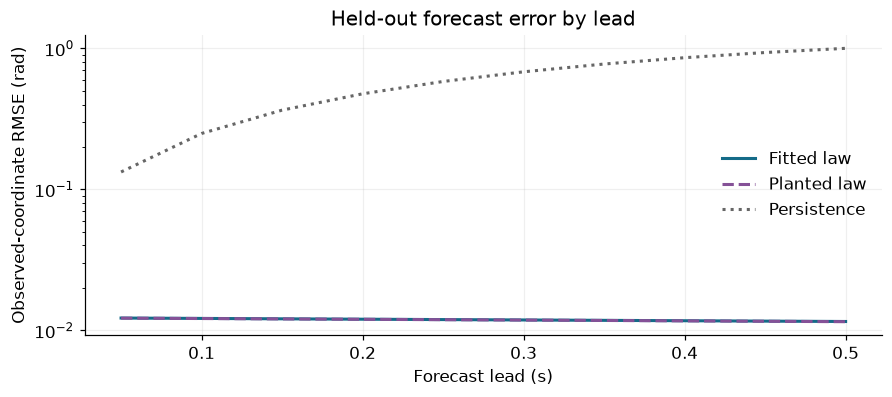

In [8]:
lead_time = dt * np.arange(1, horizon + 1)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
for label, values in forecasts.items():
    score_by_lead = rmse(values, future_truth, axis=(0, 1, 3))
    ax.plot(lead_time, score_by_lead, styles[label], color=colors[label], label=label, linewidth=2)
ax.set(
    title="Held-out forecast error by lead",
    xlabel=f"Forecast lead ({time_unit})",
    ylabel=f"Observed-coordinate RMSE ({state_units[0]})",
    yscale="log",
)
ax.legend(frameon=False)
plt.show()

### Endpoint accuracy across history lengths

A quadratic fit to the same angle history provides an endpoint value and
derivative. All widths use the same test origins. The vertical line marks the
width selected on validation.

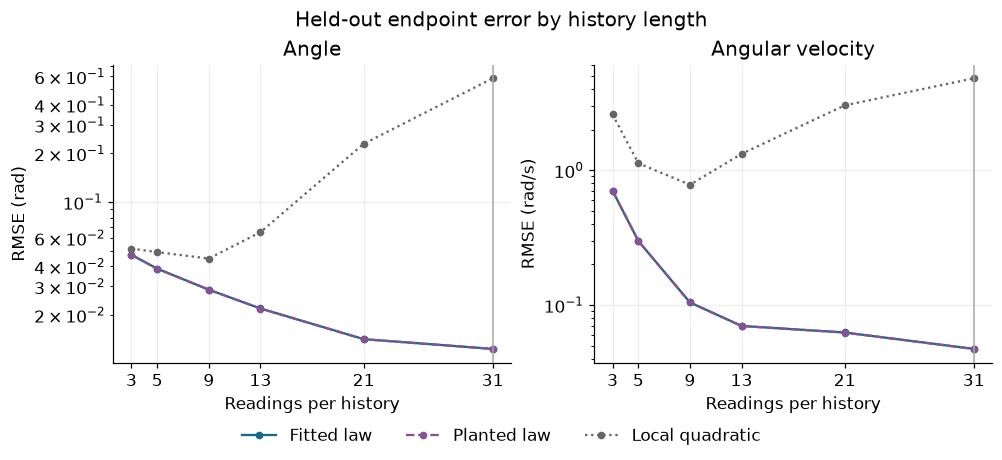

In [9]:
history_scores = {label: [] for label in ("Fitted law", "Planted law", "Local quadratic")}
for width in widths:
    windows = prefix_windows(test_readings, origins, width)
    for label, coefficients in laws.items():
        estimates, _ = reconstruct(test_readings, origins, width, coefficients)
        history_scores[label].append(rmse(estimates, current_truth, axis=(0, 1)))
    quadratic = local_quadratic(windows, np.arange(width), width - 1, dt)[..., 0, :]
    history_scores["Local quadratic"].append(rmse(quadratic, current_truth, axis=(0, 1)))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.1), layout="constrained")
for index, ax in enumerate(axes):
    for label, scores in history_scores.items():
        ax.plot(
            widths, np.array(scores)[:, index], styles.get(label, ":"),
            color=colors.get(label, "#666666"), marker="o", markersize=4, label=label,
        )
    ax.axvline(selected_width, color="#aaaaaa", linewidth=1)
    ax.set(
        xlabel="Readings per history", ylabel=f"RMSE ({state_units[index]})",
        title=state_labels[index], yscale="log", xticks=widths,
    )
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="outside lower center", ncols=3)
fig.suptitle("Held-out endpoint error by history length")
plt.show()

### Rolling reconstruction

The first test trajectory illustrates rolling inference. Shading marks the
samples before a full history is available.

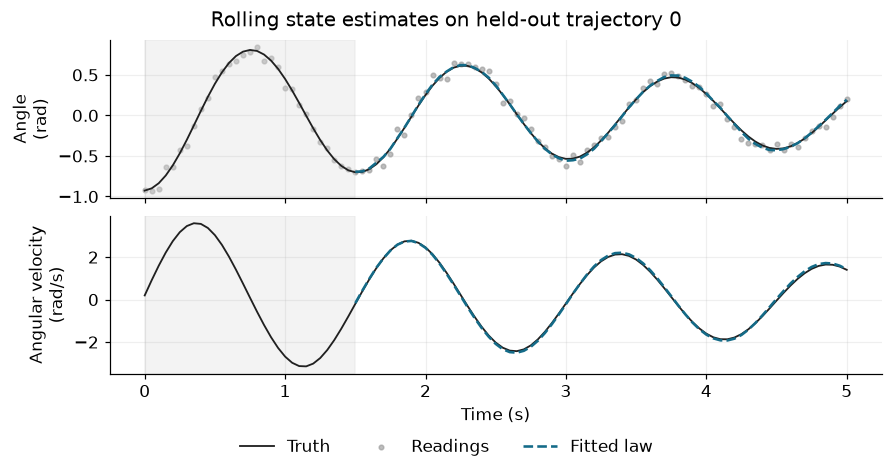

In [10]:
example_origins = np.arange(selected_width - 1, len(times))
rolling, _ = reconstruct(test_readings[:1], example_origins, selected_width, fitted)

fig, axes = plt.subplots(len(state_labels), 1, figsize=(8, 1.9 * len(state_labels) + 0.4),
                         sharex=True, layout="constrained")
for index, ax in enumerate(axes):
    ax.plot(times, test_truth[0, :, index], color="#202020", label="Truth", linewidth=1.2)
    if index < sensors:
        ax.scatter(times, test_readings[0, :, index], s=9, color="#9b9b9b", alpha=0.65, label="Readings")
    ax.plot(times[example_origins], rolling[0, :, index], "--",
            color=colors["Fitted law"], label="Fitted law", linewidth=1.7)
    ax.axvspan(times[0], times[selected_width - 1], color="#dddddd", alpha=0.35)
    ax.set_ylabel(f"{state_labels[index]}\n({state_units[index]})" if sensors == 1
                  else state_labels[index])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="outside lower center", ncols=3)
axes[-1].set_xlabel(f"Time ({time_unit})")
fig.suptitle("Rolling state estimates on held-out trajectory 0")
plt.show()

## Numerical checks

Perturb every future reading at a sentinel origin and compare the reconstructed
endpoint and forecast bit for bit. Check the training cost traces and the
finiteness of test scores.

In [11]:
origin = origins[:1]
altered = test_readings[:1].copy()
altered[:, origin[0] + 1:] += 100.0
before, _ = reconstruct(test_readings[:1], origin, selected_width, fitted)
after, _ = reconstruct(altered, origin, selected_width, fitted)
np.testing.assert_array_equal(before, after)
np.testing.assert_array_equal(rollout(before, fitted, step, horizon), rollout(after, fitted, step, horizon))

for _, _, diagnostic in candidates:
    trace = diagnostic["cost_per_sample"]
    assert np.isfinite(trace).all() and np.all(np.diff(trace) <= 0)
    assert diagnostic["converged_fraction"] == 1.0
for scores in state_scores.values():
    assert np.isfinite(scores).all()
assert np.isfinite(list(forecast_scores.values())).all()
print("Finite scores, converged training starts, and causal endpoint and rollout verified.")

Finite scores, converged training starts, and causal endpoint and rollout verified.


Compare the sparse solver with an independent finite-difference fit and check a directional derivative of the joint residual.

In [12]:
from scipy.optimize import least_squares

window = prefix_windows(test_readings[:1], origin, selected_width)[0]
endpoint_problem = TrajectoryFit(window, step, measurement_scale, defect_scale, n_coefficients=0)
initial = initialize(window, fitted)


def flat_residual(values):
    observed, defect = endpoint_problem.residuals(values.reshape(initial.shape), fitted)
    return np.r_[observed.ravel(), defect.ravel()]


reference = least_squares(flat_residual, initial.ravel(), jac="3-point",
                          ftol=1e-12, xtol=1e-12, gtol=1e-10)
assert reference.success
endpoint_error = np.max(np.abs(reference.x[-len(state_labels):] - before.ravel()))
assert endpoint_error < 1e-6

short_window = window[:, :5]
small_problem = TrajectoryFit(short_window, step, measurement_scale, defect_scale, len(terms))
states = initialize(short_window, fitted)
_, jacobian = small_problem.linearize(states, fitted)
direction = np.random.default_rng(37).normal(size=small_problem.n_states + len(terms))
epsilon = 1e-6
state_delta = epsilon * direction[:small_problem.n_states].reshape(states.shape)
coefficient_delta = epsilon * direction[small_problem.n_states:]
plus, _ = small_problem.linearize(states + state_delta, fitted + coefficient_delta)
minus, _ = small_problem.linearize(states - state_delta, fitted - coefficient_delta)
jacobian_error = np.max(np.abs((plus - minus) / (2 * epsilon) - jacobian @ direction))
assert jacobian_error < 1e-6
print(f"Maximum endpoint difference from finite-difference solver: {endpoint_error:.2e}")
print(f"Maximum directional Jacobian difference: {jacobian_error:.2e}")

Maximum endpoint difference from finite-difference solver: 7.47e-08
Maximum directional Jacobian difference: 3.48e-08


## Interpretation

All three starts converge in five updates. The fitted gravity and damping
coefficients are −18.40038 and −0.34573, close to the planted values of
−18.39375 and −0.35. The second harmonic and cubic velocity coefficients
remain near zero.

At the selected width, the 0.50 s rollout gives a pooled angle RMSE of
0.01189 rad across leads, compared with 0.01187 rad using the planted law.
The quadratic baseline has lower angular velocity error at intermediate
widths than at 31 readings, where a single polynomial spans more of the
oscillation. Coefficient recovery is evaluated within the supplied candidate
family and initial-condition range.